# Plummer Sphere

This notebook demonstrates the implementation of the **Plummer Sphere** lens model in `gwlens/lens/plummersphere.py` and demonstrates the use of its definitions.

The Plummer profile describes a finite, cored mass distribution characterized by a core radius. Unlike the Singular Isothermal Sphere (SIS), the density remains finite at the centre and falls off at large radii.

The implementation evaluates the diffraction integral numerically and constructs interpolation tables for efficient evaluation of the complex amplification factor.

### Dimensionless Lensing Potential

The dimensionless lensing potential for the Plummer sphere is

$$
\psi(x)
=
\frac{\psi_0 x_c^2}{2}
\ln\left(
1+\frac{x^2}{x_c^2}
\right)
$$

where,

- $x$ is the dimensionless image position,
- $x_c$ is the dimensionless core radius,
- $\psi_0$ is the dimensionless lensing strength.

For the numerical evaluation of the diffraction integral, the transformation

$$
u=\sqrt{2x}
$$

is used, such that the potential becomes

$$
\psi(u)
=
\frac{\psi_0 x_c^2}{2}
\ln\left(
1+\frac{u^2}{x_c^2}
\right).
$$

Here, $\psi_0=1$ is used.

### Derivatives of the Potential

The derivatives of the lensing potential are required for the integration-by-parts tail correction.

Using

$$
u=\sqrt{2x},
\qquad
\frac{du}{dx}=\frac{1}{u},
$$

the first derivative of the potential is

$$
\frac{d\psi}{du}
=
\frac{\psi_0 x_c^2 u}
{x_c^2+u^2}.
$$

Therefore,

$$

\frac{d\psi}{dx}
=
\frac{\psi_0 x_c^2}
{x_c^2+u^2}
$$

and the second derivative is

$$
\frac{d^2\psi}{dx^2}
=
-\frac{2\psi_0 x_c^2}
{\left(x_c^2+u^2\right)^2}.
$$

These derivatives are used in the asymptotic tail correction of the diffraction integral.

### Imports

In [1]:
from gwlens.lens import plummersphere
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from astropy import units as u
plotting.apply_figure_style()

import matplotlib as mpl
mpl.rcParams["text.usetex"] = False

In [2]:
help(plummersphere) #lists comments and docstrings for the plummer sphere lens module

Help on module gwlens.lens.plummersphere in gwlens.lens:

NAME
    gwlens.lens.plummersphere

FUNCTIONS
    PlummerAmplification(w, y, amp, core)
    
    compute_plummer_lens_grid(w_values, y_values, amp, core, hdf5_filename, num_processes=None)
        Computes the Point(w, y) complex amplification factor over a grid
        and stores the result in an HDF5 file.
        
        Parameters:
        - w_values (1D np.array): dimensionless frequency array
        - y_values (1D np.array): impact parameter array
        - hdf5_filename (str): path to output HDF5 file
        - num_processes (int or None): number of CPU cores to use (default: all)
    
    ddfunc_plummer(x, w, y, amp, core)
    
    dfunc_plummer(x, w, y, amp, core)
    
    func2_plummer(x, w, y, amp, core)
    
    func_plummer(x, w, y, amp, core)
    
    psi_plummer(x, amp, core)

DATA
    eps = 0.001
    mp = <mpmath.ctx_mp.MPContext object>

FILE
    /home/ansalk/GWLENS/gwlens/lens/plummersphere.py




### Wave-Optics Amplification

The amplification factor is obtained by evaluating the diffraction integral

$$
F(w,y)
=
-iw
e^{\frac{i}{2}wy^2}
\int_0^\infty
J_0\!\left(wy\sqrt{2x}\right)
\exp\!\left[
iw
\left(
x-\psi(\sqrt{2x})
\right)
\right]
dx.
$$

where

- $w$ is the dimensionless frequency,
- $y$ is the dimensionless impact parameter,
- $J_0$ denotes the Bessel function of the first kind.

For the Plummer potential,

$$
\psi(\sqrt{2x})
=
\frac{\psi_0 x_c^2}{2}
\ln\left(
1+\frac{2x}{x_c^2}
\right).
$$

The diffraction integral is evaluated using arbitrary-precision arithmetic (`mpmath`) with adaptive quadrature. To improve convergence of the oscillatory integral, integration-by-parts tail corrections are also included.

## Interpolation Tables

The complex amplification factor

$$
F(w,y)
=
F_{\rm R}(w,y)
+
iF_{\rm I}(w,y)
$$

is computed on a two-dimensional grid in $(w,y)$ and stored in an hdf5 interpolation table.

The table enables rapid evaluation of the amplification factor without recomputing the diffraction integral for each query. We now use the hdf5 data to plot $|F|$, as a demonstration.

(1000,)
(1,)
(1000, 1, 2)


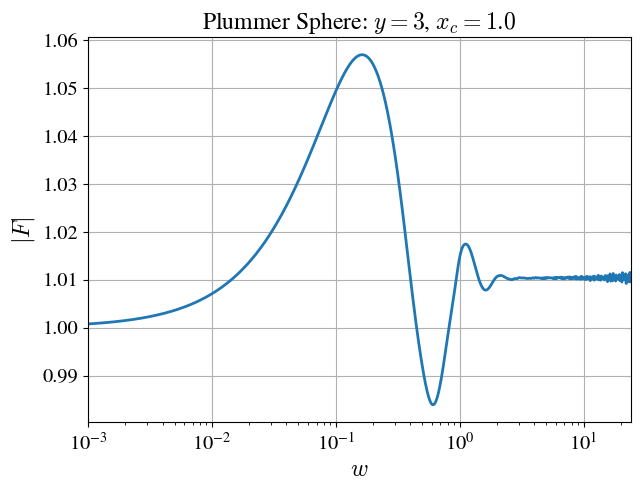

In [9]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

file = "/home/ansalk/GWLENS/outdir/interpolation/result_plummer.hdf5"

with h5py.File(file, "r") as f:
    w_values = f["w_values"][:]
    y_values = f["y_values"][:]
    data = f["results"][:]

print(w_values.shape)      # (1000,)
print(y_values.shape)      # (1,)
print(data.shape)          # (1000,1,2)

# Extract the only y slice
real = data[:, 0, 0]
imag = data[:, 0, 1]

# 1D interpolation
real_interp = interp1d(
    w_values,
    real,
    kind="cubic",
    bounds_error=False,
    fill_value="extrapolate"
)

imag_interp = interp1d(
    w_values,
    imag,
    kind="cubic",
    bounds_error=False,
    fill_value="extrapolate"
)

# Evaluate
w = np.logspace(np.log10(w_values[0]), np.log10(w_values[-1]), 1000)

F = real_interp(w) + 1j*imag_interp(w)

plt.figure(figsize=(7,5))
plt.plot(w, np.abs(F), lw=2)
plt.xscale("log")
plt.xlabel(r"$w$")
plt.xlim([w[0], w[-125]])
plt.ylabel(r"$|F|$")
plt.title(r"Plummer Sphere: $y=3$, $x_c=1.0$")
plt.grid(True)
plt.show()

### Using the defined functions to plot $|F|$

Check `gwlens\lens\plummersphere.py` for the definitions used here.

We first investigate the dependence of the amplification factor on the core radius $x_c$ for a fixed impact parameter. We then fix the core radius and vary the impact parameter $y$.

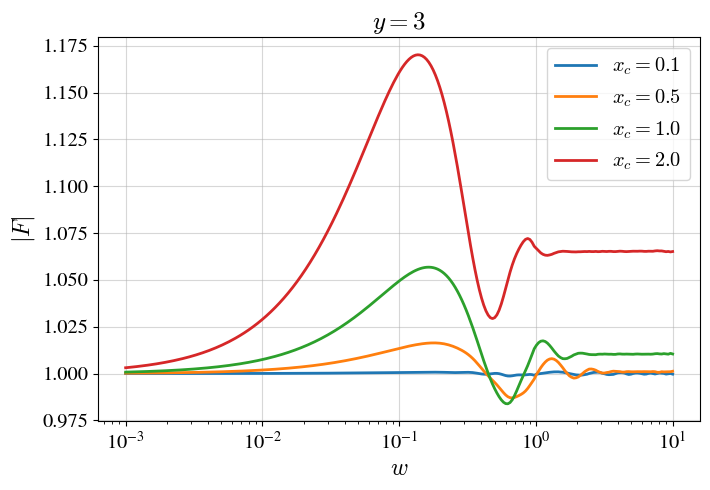

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from gwlens.tools import plotting

plotting.apply_figure_style()
import matplotlib as mpl

mpl.rcParams["text.usetex"] = False

psi0 = 1.0
y = 3.0
core_radii = [0.1, 0.5, 1.0, 2.0]

w = np.logspace(-3, 1, 250)


for rc in core_radii:

    F = np.empty(len(w), dtype=complex)

    for i, wi in enumerate(w):
        F[i] = complex(plummersphere.PlummerAmplification(wi, y, psi0, rc))

    # -----------------------
    # Magnitude
    # -----------------------
    plt.plot(
        w,
        np.abs(F),
        lw=2,
        label=fr"$x_c={rc}$"
    )

# ===========================
# Formatting
# ===========================

plt.xscale("log")
#plt.xlim(1e-3, 1e1)
plt.ylabel(r"$|F|$")
plt.xlabel(r"$w$")

plt.title(r"$y=3$", fontsize=18)

plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

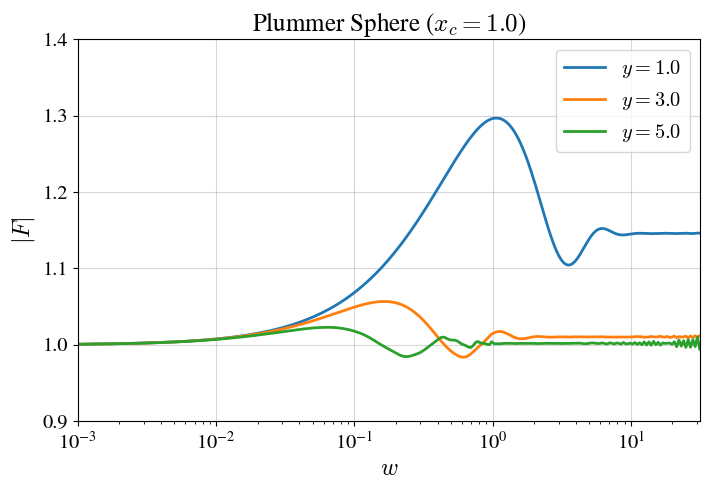

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from gwlens.tools import plotting

plotting.apply_figure_style()
mpl.rcParams["text.usetex"] = False

# -----------------------------------
# Lens parameters
# -----------------------------------
psi0 = 1.0
core = 1.0

y_values = [1.0, 3.0, 5.0]

w = np.logspace(-3, 2, 300)

# -----------------------------------
# Compute amplification
# -----------------------------------
for y in y_values:

    F = np.empty(len(w), dtype=complex)

    for i, wi in enumerate(w):
        F[i] = complex(
            plummersphere.PlummerAmplification(
                wi,
                y,
                psi0,
                core,
            )
        )

    plt.plot(
        w,
        np.abs(F),
        lw=2,
        label=fr"$y={y}$"
    )

# -----------------------------------
# Formatting
# -----------------------------------
plt.xscale("log")
plt.xlabel(r"$w$")
plt.ylabel(r"$|F|$")
plt.title(rf"Plummer Sphere ($x_c={core}$)", fontsize=18)
plt.xlim(10**-3, 10**1.5)
plt.ylim(0.9, 1.4)
plt.grid(alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### Comparison of the Plummer, CIS and SIS Profiles

The amplification factors of the Plummer sphere, Cored Isothermal Sphere (CIS), and Singular Isothermal Sphere (SIS) are compared at the same dimensionless impact parameter.

For the extended profiles, the same core radius $x_c$ (for CIS, Plummer) and lensing strength $\psi_0$ are used. This comparison shows how the different lensing potentials and mass distributions affect the wave-optics amplification pattern.


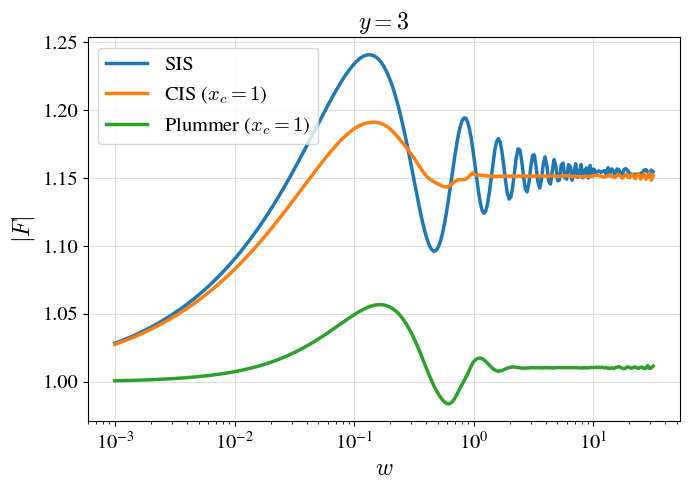

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from gwlens.lens import sis, cis, plummersphere
from gwlens.tools import plotting
from gwlens.lens.sis import calculate_F

plotting.apply_figure_style()
mpl.rcParams["text.usetex"] = False

# -----------------------------
# Lens parameters
# -----------------------------
psi0 = 1.0
core = 1.0
y = 3.0

w = np.logspace(-3, 1.5, 300)

# -----------------------------
# SIS
# -----------------------------
F_sis = np.array([
    complex(calculate_F(wi, y, n_lim=1000))
    for wi in w
])

# -----------------------------
# CIS
# -----------------------------
F_cis = np.array([
    complex(cis.CISAmplification(wi, y, psi0, core))
    for wi in w
])

# -----------------------------
# Plummer
# -----------------------------
F_plummer = np.array([
    complex(plummersphere.PlummerAmplification(wi, y, psi0, core))
    for wi in w
])

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(7, 5))

plt.plot(w, np.abs(F_sis), lw=2.5, label="SIS")
plt.plot(w, np.abs(F_cis), lw=2.5, label=r"CIS ($x_c=1$)")
plt.plot(w, np.abs(F_plummer), lw=2.5, label=r"Plummer ($x_c=1$)")

plt.xscale("log")
plt.xlabel(r"$w$")
plt.ylabel(r"$|F|$")
plt.title(r"$y=3$")

plt.grid(alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()